# TP 2 - Matrices et transformations linéaires
**Étudiant :** KHOMENKO Maxim

**Numéro du TP :** 2

**Date :** 13 Novembre 2026

**Version Python :** 3.13.5

**Bibliothèques utilisées :** numpy, matplotlib, scipy

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import linalg

## Exercice 2.1 (Opérations matricielles de base)

### a) Calculez $AB$ et $BA$. Sont-ils égaux ? Qu'en déduisez-vous ?

In [22]:
# Exercice 2.1
A = np.array([[1, 2, 3], [4, 5, 6]], dtype=float)
B = np.array([[7, 8], [9, 10], [11, 12]], dtype=float)
C = np.array([[2, -1], [1, 3]], dtype=float)

# a) produits AB et BA
AB = A @ B
BA = B @ A

print("AB =\n", AB)
print("BA =\n", BA)

AB =
 [[ 58.  64.]
 [139. 154.]]
BA =
 [[ 39.  54.  69.]
 [ 49.  68.  87.]
 [ 59.  82. 105.]]


**Résultat :** En utilisant la multiplication matricielle de NumPy :
* `A @ B` renvoie une matrice de taille $2 \times 2$.
* `B @ A` renvoie une matrice de taille $3 \times 3$.

**Déduction :** Les deux produits sont définis, mais ils n'ont pas les mêmes dimensions : $AB$ est de taille $2 \times 2$, tandis que $BA$ est de taille $3 \times 3$. Ils ne peuvent donc pas être égaux. Cet exemple illustre que la multiplication matricielle n'est pas commutative en général.

### b) Calculez $(AB)^\top$ et $B^\top A^\top$. Vérifiez l'égalité.

In [23]:
# b) transposée d'un produit
AB_T = AB.T
B_T_A_T = B.T @ A.T

print("(AB)^T =\n", AB_T)
print("B^T A^T =\n", B_T_A_T)

(AB)^T =
 [[ 58. 139.]
 [ 64. 154.]]
B^T A^T =
 [[ 58. 139.]
 [ 64. 154.]]


**Résultat :** L'utilisation de l'attribut `.T` de NumPy affiche deux résultats strictement identiques. L'égalité $(AB)^\top = B^\top A^\top$ est donc vérifiée numériquement.

### c) Calculez $C^{-1}$ avec `np.linalg.inv`. Vérifiez que $CC^{-1} = I$.

In [24]:
# c) inverse de C et vérification
C_inv = np.linalg.inv(C)
print("C^-1 =\n", C_inv)

print("C @ C^-1 =\n", C @ C_inv)

C^-1 =
 [[ 0.42857143  0.14285714]
 [-0.14285714  0.28571429]]
C @ C^-1 =
 [[1.00000000e+00 0.00000000e+00]
 [5.55111512e-17 1.00000000e+00]]


**Résultat :** La fonction `np.linalg.inv(C)` permet de calculer la matrice inverse. La multiplication matricielle `C @ C_inv` affiche bien la matrice identité $I$ (aux erreurs de précision numérique près de la machine, les valeurs hors diagonale étant extrêmement proches de $0$). L'égalité $CC^{-1} = I$ est donc vérifiée.

### d) Calculez le rang de $A$, $B$ et $C$.

In [25]:
# d) calcul du rang
print("rang(A) =", np.linalg.matrix_rank(A))
print("rang(B) =", np.linalg.matrix_rank(B))
print("rang(C) =", np.linalg.matrix_rank(C))

rang(A) = 2
rang(B) = 2
rang(C) = 2


**Résultat :** En utilisant la fonction `np.linalg.matrix_rank` de NumPy, on obtient :
* $rang(A) = 2$
* $rang(B) = 2$
* $rang(C) = 2$

### Conclusion de l'exercice 2.1

J'ai montré que le produit matriciel n'est pas commutatif, puisque $AB$ est de taille $2 \times 2$ alors que $BA$ est de taille $3 \times 3$. J'ai aussi vérifié sur cet exemple que $(AB)^\top = B^\top A^\top$. Enfin, j'ai calculé $C^{-1}$ avec `np.linalg.inv`, vérifié que $CC^{-1} = I$ aux erreurs d'arrondi près, et constaté que $A$, $B$ et $C$ sont toutes de rang $2$.

## Exercice 2.2 (Matrices spéciales)

### a) Construisez la matrice de rotation d'angle $\theta$ dans $\mathbb{R}^2$ et vérifiez que $R(\theta)^\top R(\theta) = I$ pour $\theta = \pi/4$.

In [26]:
# Exercice 2 --- matrice de rotation
# a) matrice de rotation
def rotation(theta):
    return np.array([[np.cos(theta), -np.sin(theta)],
                     [np.sin(theta), np.cos(theta)]])

R = rotation(np.pi/4)
print("R^T @ R =\n", R.T @ R)  # doit etre proche de I

R^T @ R =
 [[ 1.00000000e+00 -1.01465364e-17]
 [-1.01465364e-17  1.00000000e+00]]


**Résultat :** L'exécution du code renvoie la matrice identité $I_2$, aux erreurs de précision près. Les coefficients hors diagonale valent environ $-1.01 \times 10^{-17}$ (liés au calcul sur des nombres flottants) au lieu de $0$. L'égalité $R(\theta)^\top R(\theta) = I$ est donc vérifiée.

### b) Construisez la matrice de projection orthogonale $P = uu^\top$ sur le vecteur $u = (1, 2)^\top / \left\|(1, 2)^\top\right\|_2$. Vérifiez que $P^2 = P$ et $P^\top = P$.

In [27]:
# b) matrice de projection orthogonale
# definition du vecteur colonne (1, 2)^T
v = np.array([[1], [2]], dtype=float)

# normalisation pour obtenir u
u = v / np.linalg.norm(v)

# construction de la matrice P = u * u^T
P = u @ u.T

print("P =\n", P)
print("P @ P =\n", P @ P)
print("P.T =\n", P.T)

P =
 [[0.2 0.4]
 [0.4 0.8]]
P @ P =
 [[0.2 0.4]
 [0.4 0.8]]
P.T =
 [[0.2 0.4]
 [0.4 0.8]]


**Résultat :** NumPy renvoie

$P = \begin{pmatrix} 0.2 & 0.4 \\ 0.4 & 0.8 \end{pmatrix}$

* Pour $P^2$, l'affichage de $P @ P$ renvoie exactement la même matrice. L'égalité $P^2 = P$ est donc vérifiée, la matrice est bien idempotente.
* Pour $P^\top$, l'affichage de $P.T$ renvoie encore exactement la même matrice. L'égalité $P^\top = P$ est donc vérifiée, la matrice est bien symétrique.

### c) Construisez une matrice symétrique $5 \times 5$ aléatoire $S = A + A^\top$ où $A$ est une matrice aléatoire. Vérifiez numériquement que $S = S^\top$.

In [28]:
# c) matrice symétrique aléatoire
np.random.seed(0)
# generation d'une matrice aleatoire 5x5
A_alea = np.random.randn(5, 5)

# construction de S
S = A_alea + A_alea.T

# verification numerique
print("S =\n", S)
print("S.T =\n", S.T)

# verification
print("L'égalité S == S.T est-elle vérifiée partout ?", (S == S.T).all())

S =
 [[ 3.52810469 -0.57712067  1.12278156  2.57456753 -0.68543183]
 [-0.57712067  1.90017684  1.3029163   1.39086022  1.0642171 ]
 [ 1.12278156  1.3029163   1.52207545 -0.08348325  1.30829943]
 [ 2.57456753  1.39086022 -0.08348325  0.6261354  -1.59626076]
 [-0.68543183  1.0642171   1.30829943 -1.59626076  4.53950925]]
S.T =
 [[ 3.52810469 -0.57712067  1.12278156  2.57456753 -0.68543183]
 [-0.57712067  1.90017684  1.3029163   1.39086022  1.0642171 ]
 [ 1.12278156  1.3029163   1.52207545 -0.08348325  1.30829943]
 [ 2.57456753  1.39086022 -0.08348325  0.6261354  -1.59626076]
 [-0.68543183  1.0642171   1.30829943 -1.59626076  4.53950925]]
L'égalité S == S.T est-elle vérifiée partout ? True


**Résultat :** Après avoir généré une matrice aléatoire $A$ et calculé $S = A + A^\top$, NumPy renvoie une matrice de taille $5 \times 5$. L'affichage de la matrice $S$ et de sa transposée $S^\top$ montre des coefficients strictement identiques à toutes les positions. L'égalité $S = S^\top$ est donc vérifiée numériquement.

### Conclusion de l'exercice 2.2

J'ai construit la matrice de rotation $R(\pi/4)$ et vérifié numériquement que $R(\pi/4)^\top R(\pi/4) = I$, ce qui illustre qu'elle est orthogonale. J'ai également construit la matrice de projection $P = uu^\top$ et vérifié via les affichages de NumPy qu'elle est idempotente et symétrique. Enfin, j'ai vérifié numériquement que la matrice $S = A + A^\top$ générée aléatoirement est bien symétrique, en constatant au passage que la comparaison de matrices informatiques nécessite de prendre en compte les infimes erreurs d'arrondi des nombres flottants.

## Exercice 2.3 (Visualisation des transformations linéaires dans $\mathbb{R}^2$)

On va visualiser l'effet de différentes transformations sur le carré unité $[0, 1]^2$.

### a) Définissez les quatre coins du carré unité comme colonnes d'une matrice $X \in \mathbb{R}^{2 \times 4}$.

In [29]:
# Exercice 2.3 --- Visualisation
# a) definition des coins du carre unite (matrice 2x4)
coins = np.array([[0, 1, 1, 0], [0, 0, 1, 1]], dtype=float)

**Résultat :** Les quatre coins du carré unité sont $(0, 0)$, $(1, 0)$, $(1, 1)$ et $(0, 1)$. En plaçant les abscisses sur la première ligne et les ordonnées sur la seconde, on obtient la matrice $2 \times 4$ :

$X = \begin{pmatrix} 0 & 1 & 1 & 0 \\ 0 & 0 & 1 & 1 \end{pmatrix}$

### b) Appliquez $X \mapsto MX$ pour $M_1$, $M_2$, $M_3$, $M_4$ et affichez le quadrilatère obtenu, avec le carré original en pointillés.

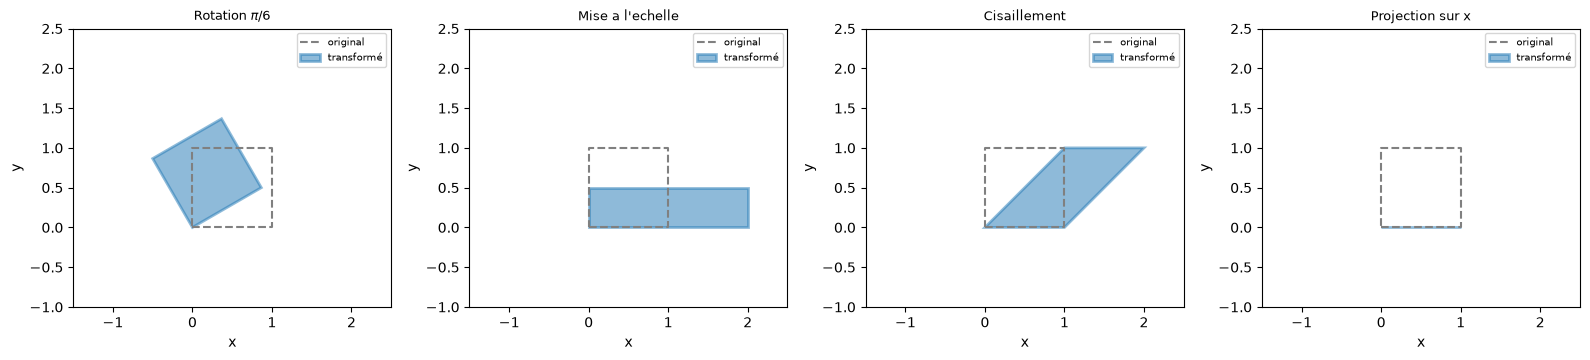

In [30]:
# b) application des transformations et visualisation
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
transformations = {
    r"Rotation $\pi/6$": rotation(np.pi/6),
    "Mise a l'echelle": np.array([[2., 0.], [0., 0.5]]),
    "Cisaillement": np.array([[1., 1.], [0., 1.]]),
    "Projection sur x": np.array([[1., 0.], [0., 0.]])
}

for ax, (titre, M) in zip(axes, transformations.items()):
    # application de la transformation M * X
    carre_t = M @ coins

    # carre original en pointillés
    ax.plot(np.append(coins[0], coins[0][0]), np.append(coins[1], coins[1][0]), linestyle='--', color='gray', label='original')

    # quadrilatère transforme
    ax.fill(carre_t[0], carre_t[1], alpha=0.5, edgecolor='C0', linewidth=2, label='transformé')
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    ax.set_aspect('equal')
    ax.legend(fontsize=7)
    ax.set_title(titre, fontsize=9)
    ax.set_xlim(-1.5, 2.5)
    ax.set_ylim(-1, 2.5)

plt.tight_layout()
plt.show()

**Résultat :** L'application de la multiplication matricielle `M @ coins` dans Python génère ces 4 graphiques :
* La matrice $M_1$ (rotation) fait tourner le carré de 30° autour de l'origine.
* La matrice $M_2$ (mise à l'échelle) étire le carré d'un facteur 2 sur l'axe $x$ et l'écrase d'un facteur 0.5 sur l'axe $y$, formant un rectangle.
* La matrice $M_3$ (cisaillement) incline les bords verticaux vers la droite, formant un parallélogramme.
* La matrice $M_4$ (projection) écrase totalement le carré sur l'axe des abscisses. Le carré est écrasé sur le segment $[0, 1]$ de l'axe des abscisses, dont l'aire est nulle.

### c) Pour chaque transformation, indiquez si elle conserve les distances, les angles, les aires. Reliez à la valeur de $|\det(M)|$.

In [31]:
# c) calcul du déterminant pour chaque matrice
for titre, M in transformations.items():
    det_M = np.linalg.det(M)
    print(f"|det(M)| pour {titre} : {abs(det_M):.2f}")

|det(M)| pour Rotation $\pi/6$ : 1.00
|det(M)| pour Mise a l'echelle : 1.00
|det(M)| pour Cisaillement : 1.00
|det(M)| pour Projection sur x : 0.00


**Résultat :** L'observation des figures et le calcul numérique du déterminant donnent le bilan suivant :

* $M_1$ (Rotation) : Conserve les distances, les angles et les aires.
* $M_2$ (Mise à l'échelle) : Ne conserve que les aires (ni les distances, ni les angles).
* $M_3$ (Cisaillement) : Ne conserve que les aires (ni les distances, ni les angles).
* $M_4$ (Projection) : Ne conserve ni les distances ni les angles. Elle réduit l'aire à zéro en écrasant le carré sur l'axe des abscisses.

**Lien avec le déterminant :**
La valeur absolue du déterminant $|\det(M)|$ correspond au facteur de multiplication des aires. Pour $M_1, M_2$ et $M_3$, on obtient $|\det(M)| = 1$, ce qui confirme la conservation de l'aire. Pour $M_4$, on obtient $|\det(M)| = 0$, ce qui confirme que la figure a été écrasée et que son aire est devenue nulle.

### Conclusion de l'exercice 2.3

J'ai appris à ranger les coins du carré unité dans les colonnes d'une matrice $X \in \mathbb{R}^{2 \times 4}$, ce qui permet d'appliquer une transformation $M$ aux quatre coins en une seule opération `M @ coins`. J'ai visualisé l'effet d'une rotation, d'une mise à l'échelle, d'un cisaillement et d'une projection et constaté que seule la rotation conserve les distances, les angles et les aires. J'ai vérifié que l'aire finale de la figure correspond à la valeur $|\det(M)|$. Enfin, j'ai constaté avec la mise à l'échelle et le cisaillement qu'un déterminant égal à 1 garantit la conservation de l'aire, mais pas celle des distances ni des angles.

## Exercice 2.4 (Rang et noyau)

### a) Calculez le rang des matrices $D$ et $E$.

In [32]:
# Exercice 4
D = np.array([[1, 2, 3], [2, 4, 6], [1, 1, 1]], dtype=float)
E = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1], [1, 1, 1]], dtype=float)

# a) rang de D et E
rang_D = np.linalg.matrix_rank(D)
rang_E = np.linalg.matrix_rank(E)

print("rang(D) =", rang_D)
print("rang(E) =", rang_E)

rang(D) = 2
rang(E) = 3


**Résultat :** En utilisant la fonction `np.linalg.matrix_rank`, NumPy renvoie
* $rang(D) = 2$
* $rang(E) = 3$

### b) Pour la matrice $D$, trouvez une base du noyau en résolvant $Dx = 0$ avec `scipy.linalg.null_space`.

In [33]:
# b) base du noyau de D
noyau_D = linalg.null_space(D)
print("Base du noyau de D :\n", noyau_D)

Base du noyau de D :
 [[ 0.40824829]
 [-0.81649658]
 [ 0.40824829]]


**Résultat :** En appliquant la fonction `scipy.linalg.null_space`, la machine renvoie le vecteur de base orthonormé pour le noyau : $x \approx \begin{pmatrix} 0.408 \\ -0.816 \\ 0.408 \end{pmatrix}$

### c) Vérifiez le théorème du rang $rang(D) + \dim(\ker D) = 3$.

In [34]:
# c) verification du théorème du rang
dim_ker = noyau_D.shape[1] # Nombre de colonnes de la base du noyau
print(f"Vérification : rang(D) + dim(ker D) = {np.linalg.matrix_rank(D)} + {dim_ker} = {np.linalg.matrix_rank(D) + dim_ker}")

Vérification : rang(D) + dim(ker D) = 2 + 1 = 3


**Résultat :** Les sorties informatiques précédentes permettent de vérifier ce théorème :
* La fonction `matrix_rank` a calculé un rang de 2 pour la matrice $D$.
* La fonction `null_space` a renvoyé une base constituée d'une seule colonne, ce qui signifie que $\dim(\ker D) = 1$.
* L'addition des deux donne $2 + 1 = 3$, ce qui correspond bien au nombre de colonnes ($n=3$) de la matrice $D$. Le théorème du rang est vérifié numériquement.

### Conclusion de l'exercice 2.4

J'ai pu constater qu'une matrice n'est pas toujours de rang plein : $rang(D) = 2$ (strictement inférieur à $\min(m, n)$), tandis que $E$ atteint son rang maximum en colonnes ($rang(E) = 3$). J'ai également extrait une base orthonormée du noyau de $D$ à l'aide de `scipy.linalg.null_space`, qui m'a renvoyé un vecteur colonne unique. Enfin, j'ai pu vérifier numériquement le théorème du rang en additionnant le rang calculé (2) et la dimension de ce noyau (1), retrouvant bien le nombre total de colonnes de la matrice.

## Conclusion générale

Dans ce TP, j'ai manipulé les produits, inverses et rangs de matrices avec `numpy.linalg`, en vérifiant les propriétés théoriques. J'ai visualisé l'effet géométrique de quatre transformations du plan et constaté que $|\det(M)|$ donne le facteur de variation des aires, tandis que la conservation des distances et des angles exige en plus $M^\top M = I$. J'ai enfin illustré le théorème du rang sur la matrice $D$ : $\text{rang}(D) + \dim(\ker D) = 2 + 1 = 3$.